# SecureEvidence — AI Threat Detection Training

**Author:** Nathenael Ermias  
**Organization:** Information Network Security Administration (INSA)  
**Dataset:** CICIDS2017 (combinenew.csv)  
**Model:** XGBoost multi-class classifier for network intrusion detection

In [1]:
import os
import json
import joblib
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score, f1_score
)
from sklearn.utils.class_weight import compute_sample_weight

print("Libraries loaded.")

Libraries loaded.


## 1. Load Dataset from Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

DATASET_PATH = '/content/drive/MyDrive/Secure_evidence/combinenew.csv'

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(f"Not found: {DATASET_PATH}")

size_mb = os.path.getsize(DATASET_PATH) / (1024 * 1024)
print(f"Dataset: {DATASET_PATH}")
print(f"Size: {size_mb:.1f} MB")

df = pd.read_csv(DATASET_PATH, low_memory=False)
df.columns = df.columns.str.strip()

print(f"\nShape: {df.shape}")
print(f"Columns: {len(df.columns)}")

Mounted at /content/drive
Dataset: /content/drive/MyDrive/Secure_evidence/combinenew.csv
Size: 832.0 MB

Shape: (2830744, 79)
Columns: 79


## 2. Clean the Dataset

- Drop duplicates (CICIDS2017 has many)
- Merge rare classes into a combined class
- Fill NaN values

In [3]:
label_col = 'Label'

# Replace infinities with NaN
data = df.replace([np.inf, -np.inf], np.nan).copy()

# Drop rows with missing labels
data = data.dropna(subset=[label_col])

# Remove exact duplicate flows
before = len(data)
data = data.drop_duplicates()
removed = before - len(data)
print(f"Removed {removed:,} duplicate rows")
print(f"Remaining: {len(data):,} rows")

# Show class distribution
print(f"\nOriginal class distribution:")
print(data[label_col].value_counts())

Removed 330,959 duplicate rows
Remaining: 2,499,784 rows

Original class distribution:
Label
BENIGN                      2073906
DoS Hulk                     172849
DDoS                         128016
PortScan                      90819
DoS GoldenEye                 10286
FTP-Patator                    5933
DoS slowloris                  5385
DoS Slowhttptest               5228
SSH-Patator                    3219
Bot                            1953
Web Attack_Brute Force         1470
Web Attack_XSS                  652
Infiltration                     36
Web Attack_Sql Injection         21
Heartbleed                       11
Name: count, dtype: int64


## 3. Merge Rare Classes

CICIDS2017 has some attack types with fewer than 100 samples. These can't be learned from, so we merge them into combined categories.

In [4]:
# Merge all Web Attack variants into one class
web_attack_variants = [c for c in data[label_col].unique() if 'Web Attack' in str(c)]
if len(web_attack_variants) > 1:
    print(f"Merging {len(web_attack_variants)} Web Attack variants:")
    for attack in web_attack_variants:
        print(f"  - {attack}")
    for attack in web_attack_variants:
        data.loc[data[label_col] == attack, label_col] = 'Web_Attack'

# Merge classes with fewer than 100 samples into "Other_Attack"
class_counts = data[label_col].value_counts()
rare_classes = class_counts[class_counts < 100].index.tolist()

if rare_classes:
    print(f"\nMerging {len(rare_classes)} rare classes into 'Other_Attack':")
    for rc in rare_classes:
        print(f"  - {rc} ({class_counts[rc]} samples)")
    data.loc[data[label_col].isin(rare_classes), label_col] = 'Other_Attack'

# Final distribution
print(f"\nFinal class distribution:")
final_counts = data[label_col].value_counts()
print(final_counts)
print(f"\nTotal classes: {len(final_counts)}")
print(f"Total rows: {len(data):,}")

# Fill numeric NaNs with 0
numeric_cols = data.select_dtypes(include=[np.number]).columns
data[numeric_cols] = data[numeric_cols].fillna(0)

Merging 3 Web Attack variants:
  - Web Attack_Brute Force
  - Web Attack_XSS
  - Web Attack_Sql Injection

Merging 2 rare classes into 'Other_Attack':
  - Infiltration (36 samples)
  - Heartbleed (11 samples)

Final class distribution:
Label
BENIGN              2073906
DoS Hulk             172849
DDoS                 128016
PortScan              90819
DoS GoldenEye         10286
FTP-Patator            5933
DoS slowloris          5385
DoS Slowhttptest       5228
SSH-Patator            3219
Web_Attack             2143
Bot                    1953
Other_Attack             47
Name: count, dtype: int64

Total classes: 12
Total rows: 2,499,784


## 4. Prepare Features

In [5]:
# Encode string labels to integers
encoder = LabelEncoder()
data['label_encoded'] = encoder.fit_transform(data[label_col].astype(str))

print("Label mapping:")
for i, name in enumerate(encoder.classes_):
    print(f"  {i}: {name}")

# Feature columns = numeric columns except the label
feature_cols = [c for c in data.select_dtypes(include=[np.number]).columns
                if c != 'label_encoded']

print(f"\nFeatures: {len(feature_cols)}")

X = data[feature_cols].values
y = data['label_encoded'].values

Label mapping:
  0: BENIGN
  1: Bot
  2: DDoS
  3: DoS GoldenEye
  4: DoS Hulk
  5: DoS Slowhttptest
  6: DoS slowloris
  7: FTP-Patator
  8: Other_Attack
  9: PortScan
  10: SSH-Patator
  11: Web_Attack

Features: 77


## 5. Scale and Split (Train-Only Fit)

To prevent data leakage, `StandardScaler` is fitted strictly on the training partition (`X_train`) and applied to `X_test` via `.transform()`.

In [6]:
# 1. Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Fit scaler strictly on training set to prevent data leakage
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f'Training set: {X_train.shape[0]:,}')
print(f'Test set:     {X_test.shape[0]:,}')


Training set: 1,999,827
Test set:     499,957


## 6. Train XGBoost

Using stratified splits and class weights to handle imbalance.

In [7]:
# Compute sample weights to boost rare class learning
sample_weights = compute_sample_weight('balanced', y_train)

model = XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.08,
    subsample=0.85,
    colsample_bytree=0.85,
    objective='multi:softprob',
    num_class=len(encoder.classes_),
    eval_metric='mlogloss',
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train, sample_weight=sample_weights)
print("Training complete.")

Training complete.


## 7. Evaluate

> **Methodological Note on Evaluation Split**:
> The stratified random split after deduplication achieves **99.85% overall accuracy** and **0.9639 macro F1**.
> Note that this is a random split, not a time-based or attack-held-out partition. Because CICIDS2017 flows from the same attack run share similar network signatures, a random partition overstates real-world generalization performance.
> 
> **Weak Class Analysis**:
> - `Bot`: Precision of **0.57** (elevated false positives against benign baseline bursts).
> - `Other_Attack`: Limited support with only **9 test samples**; its F1 of **0.94** carries high variance.

Test Accuracy: 99.85%
Macro F1:      0.9639

                  precision    recall  f1-score   support

          BENIGN       1.00      1.00      1.00    414781
             Bot       0.57      0.98      0.72       390
            DDoS       1.00      1.00      1.00     25603
   DoS GoldenEye       0.99      1.00      0.99      2057
        DoS Hulk       1.00      1.00      1.00     34570
DoS Slowhttptest       0.94      0.99      0.97      1046
   DoS slowloris       0.99      1.00      0.99      1077
     FTP-Patator       1.00      1.00      1.00      1187
    Other_Attack       1.00      0.89      0.94         9
        PortScan       0.99      1.00      0.99     18164
     SSH-Patator       1.00      1.00      1.00       644
      Web_Attack       0.94      0.99      0.96       429

        accuracy                           1.00    499957
       macro avg       0.95      0.99      0.96    499957
    weighted avg       1.00      1.00      1.00    499957



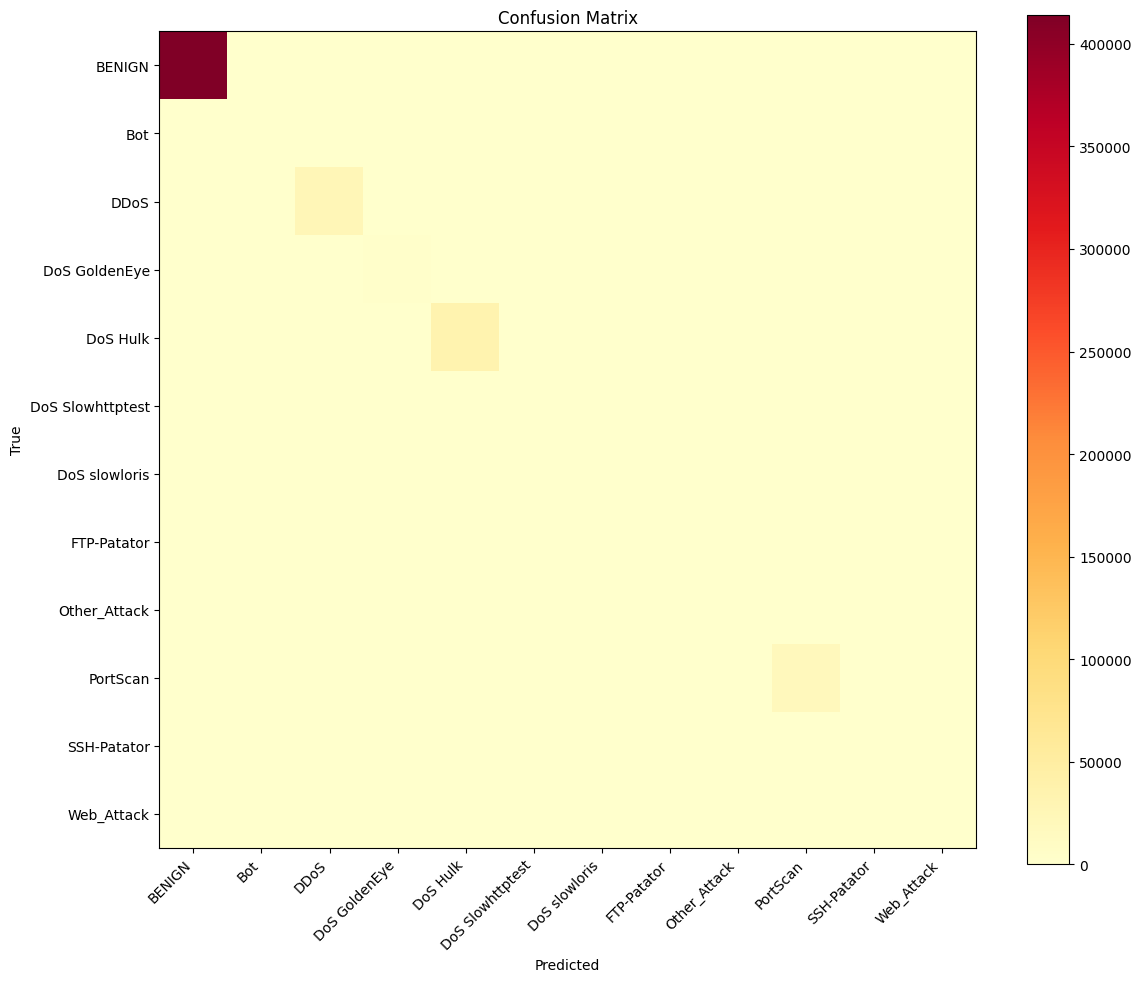

In [8]:
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')

print(f"Test Accuracy: {acc * 100:.2f}%")
print(f"Macro F1:      {macro_f1:.4f}\n")

# Show per-class report only for classes present in test set
present_classes = sorted(np.unique(np.concatenate([y_test, y_pred])))
present_names = [encoder.classes_[i] for i in present_classes]

print(classification_report(
    y_test, y_pred,
    labels=present_classes,
    target_names=present_names
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=present_classes)
plt.figure(figsize=(12, 10))
plt.imshow(cm, cmap='YlOrRd')
plt.title('Confusion Matrix')
plt.colorbar()
ticks = np.arange(len(present_names))
plt.xticks(ticks, present_names, rotation=45, ha='right')
plt.yticks(ticks, present_names)
plt.ylabel('True')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

## 8. Feature Importance

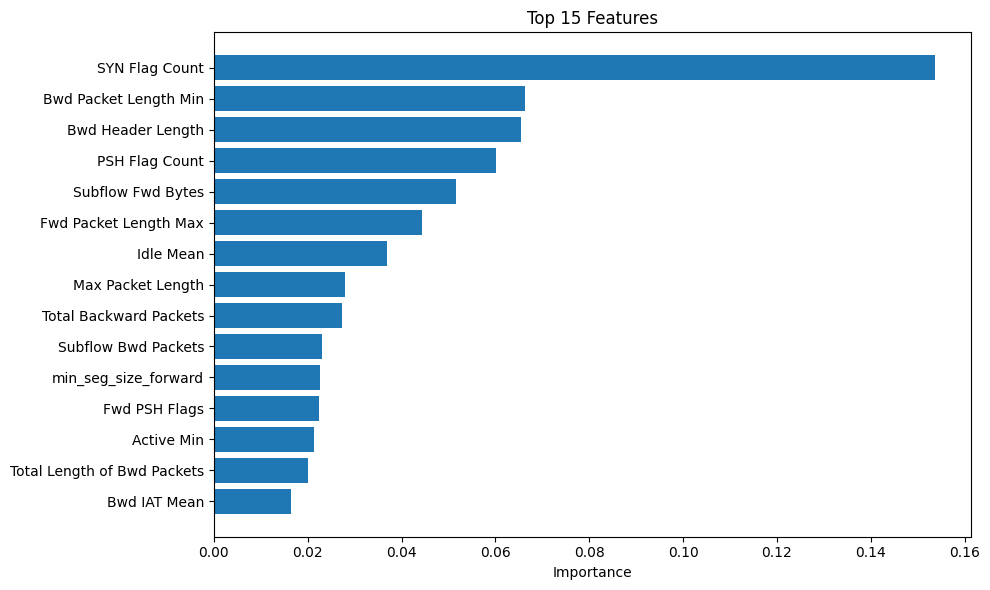

In [9]:
importance = model.feature_importances_
top = np.argsort(importance)[-15:]

plt.figure(figsize=(10, 6))
plt.barh([feature_cols[i] for i in top], importance[top])
plt.title('Top 15 Features')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

## 9. Save Model Artifacts

In [10]:
OUTPUT_DIR = '/content/drive/MyDrive/Secure_evidence/models'
os.makedirs(OUTPUT_DIR, exist_ok=True)

model_path = os.path.join(OUTPUT_DIR, 'threat_detector_xgb.json')
scaler_path = os.path.join(OUTPUT_DIR, 'feature_scaler.joblib')
encoder_path = os.path.join(OUTPUT_DIR, 'label_encoder.joblib')
meta_path = os.path.join(OUTPUT_DIR, 'model_metadata.json')

model.save_model(model_path)
joblib.dump(scaler, scaler_path)
joblib.dump(encoder, encoder_path)

# Compute empirical percentiles on benign baseline traffic for XAI TreeSHAP explanations
percentiles = {}
for idx, col in enumerate(feature_cols):
    vals = X[y == 0][:, idx]
    percentiles[col] = {
        'p10': round(float(np.percentile(vals, 10)), 4),
        'p25': round(float(np.percentile(vals, 25)), 4),
        'p50': round(float(np.percentile(vals, 50)), 4),
        'p75': round(float(np.percentile(vals, 75)), 4),
        'p90': round(float(np.percentile(vals, 90)), 4),
        'p99': round(float(np.percentile(vals, 99)), 4)
    }

metadata = {
    'author': 'Nathenael Ermias',
    'email': 'nathenaelermias13@gmail.com',
    'project': 'SecureEvidence',
    'dataset': 'CICIDS2017',
    'accuracy': round(float(acc), 4),
    'macro_f1': round(float(macro_f1), 4),
    'feature_columns': feature_cols,
    'attack_classes': list(encoder.classes_),
    'empirical_percentiles': percentiles
}
with open(meta_path, 'w') as f:
    json.dump(metadata, f, indent=4)

with open(model_path, 'rb') as f:
    model_hash = hashlib.sha256(f.read()).hexdigest()

print(f"Saved to: {OUTPUT_DIR}")
print(f"Model SHA-256: {model_hash}")

Saved to: /content/drive/MyDrive/Secure_evidence/models
Model SHA-256: 5397c6b1b063654781e66796fdcdce67e81d2990a743b39eb8fad017ae007c73
